In [1]:
import sys, os; sys.path.insert(0, os.path.join(os.path.dirname(os.path.abspath('')), 'Utilities'))
import numpy as np
import matplotlib.pyplot as plt
import hyperillumination_phasecurve_utils as hipc
import kepler_utils as k 

looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected


In [2]:
# Data from K2-141b (Malavolta et al. 2018, Barragán et al. 2018)
period=0.2803                               #orbital period [days]
rp = 0.0204                                 #planet radius [stellar radii / rs]
rs = 0.68                                   # stellar radius [solar radii]
a_AU = 0.007                                #semi-major axis [AU]   
a = k.AU_to_RS(a_AU, rs)                    #semi-major axis [stellar radii] 
incl = 86.3                                 #orbital inclination [degrees]
ecc = 0.                                    #eccentricity
w = 90.                                     #longitude of periastron [degrees] 
fp = 142e-6                                 #planet-to-star flux ratio / occultation depth Fp/Fs(alpha=0) (integrated day-side flux) - from Zieba 2022, using Spitzer’s IRAC Channel 2 at 4.5 µm
T_eff = 4570                                # stellar effective temperature [K]

u = [0.1, 0.3]                              # Stellar limb darkening coefficients [u1, u2] (placeholders, not from K2-141 data, will be set by theoretical stellar atmosphere models)

Ag = 0.28                                   # Geometric albedo from Zieba 2022, using Spitzer’s IRAC Channel 2 at 4.5 µm
A_B = 3/2*Ag                                # Assuming Lambertian reflectance. PROBABLY UNPHYSICAL!
A = A_B                                     # ASSUMPTION (!): Band-integrated albedo of rocky surface = A_B

### Radiant Intensity Lightcurve

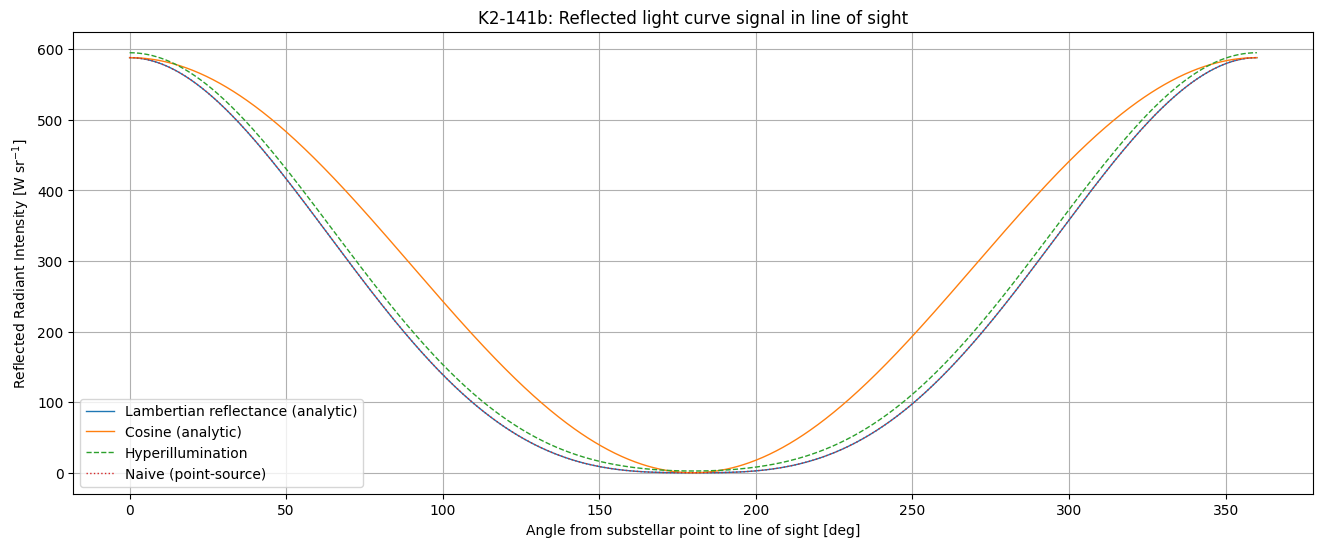

In [3]:
epsilon = np.linspace(0, 360, 1000)

L_kopal = hipc.reflected_lightcurve(np.radians(epsilon), rp, 1, a, T_eff, insolation_model="kopal", unit="radiant intensity", A=A)
L_naive = hipc.reflected_lightcurve(np.radians(epsilon), rp, 1, a, T_eff, insolation_model="naive", unit="radiant intensity", A=A)
L_cos = (np.cos(np.radians(epsilon))+1)/2*np.max(L_naive)
L_lambertian = hipc.lambertian_reflectance(np.radians(epsilon), rp, 1, a, T_eff, unit="radiant intensity", A=A)

plt.figure(figsize=(16, 6))
plt.plot(epsilon, L_lambertian, linewidth=1, label="Lambertian reflectance (analytic)")
plt.plot(epsilon, L_cos, linewidth=1, label="Cosine (analytic)")
plt.plot(epsilon, L_kopal, linewidth=1, linestyle="--", label="Hyperillumination")
plt.plot(epsilon, L_naive, linewidth=1, linestyle=":", label="Naive (point-source)")

plt.xlabel("Angle from substellar point to line of sight [deg]")
plt.ylabel(r"Reflected Radiant Intensity [W sr$^{-1}$]")
plt.title("K2-141b: Reflected light curve signal in line of sight")
plt.legend()
plt.grid()

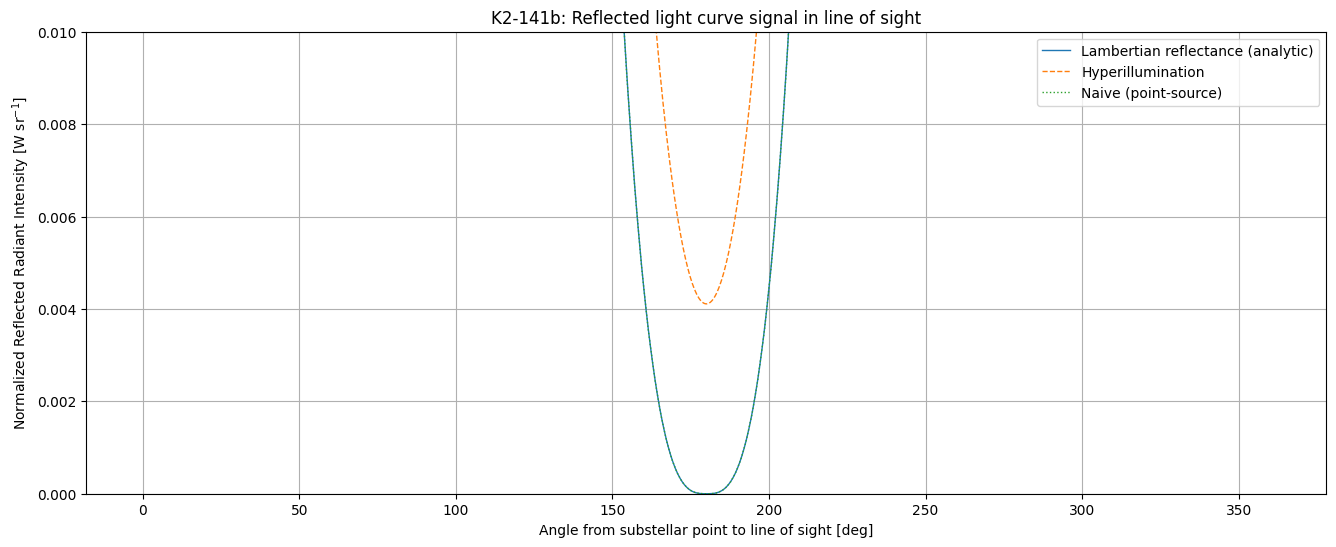

In [4]:
amp = np.max(L_lambertian)
plt.figure(figsize=(16, 6))
plt.plot(epsilon, L_lambertian/amp, linewidth=1, label="Lambertian reflectance (analytic)")
#plt.plot(epsilon, L_cos/amp, linewidth=1, label="Cosine (analytic)")
plt.plot(epsilon, L_kopal/amp, linewidth=1, linestyle="--", label="Hyperillumination")
plt.plot(epsilon, L_naive/amp, linewidth=1, linestyle=":", label="Naive (point-source)")

plt.xlabel("Angle from substellar point to line of sight [deg]")
plt.ylabel(r"Normalized Reflected Radiant Intensity [W sr$^{-1}$]")
plt.title("K2-141b: Reflected light curve signal in line of sight")
plt.legend()
plt.ylim(0., 0.01)
plt.grid()

### Normalized Lightcurve Fp/Fs

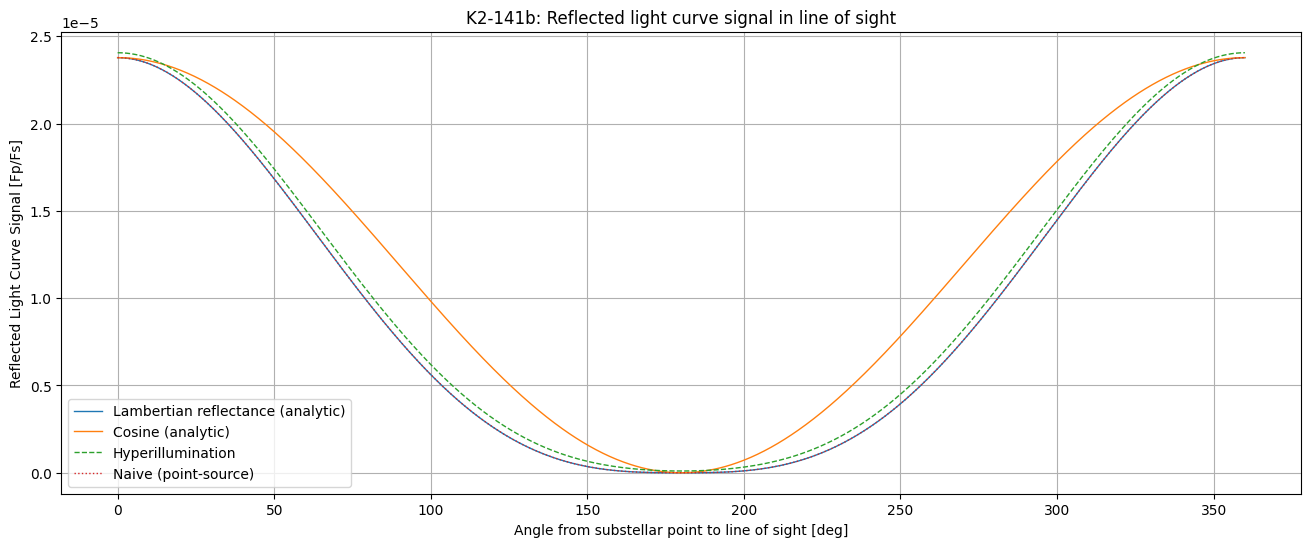

In [5]:
epsilon = np.linspace(0, 360, 1000)

L_kopal = hipc.reflected_lightcurve(np.radians(epsilon), rp, 1, a, T_eff, insolation_model="kopal", unit="normalized", A=A)
L_naive = hipc.reflected_lightcurve(np.radians(epsilon), rp, 1, a, T_eff, insolation_model="naive", unit="normalized", A=A)
L_cos = (np.cos(np.radians(epsilon))+1)/2*np.max(L_naive)
L_lambertian = hipc.lambertian_reflectance(np.radians(epsilon), rp, 1, a, T_eff, unit="normalized", A=A)

plt.figure(figsize=(16, 6))
plt.plot(epsilon, L_lambertian, linewidth=1, label="Lambertian reflectance (analytic)")
plt.plot(epsilon, L_cos, linewidth=1, label="Cosine (analytic)")
plt.plot(epsilon, L_kopal, linewidth=1, linestyle="--", label="Hyperillumination")
plt.plot(epsilon, L_naive, linewidth=1, linestyle=":", label="Naive (point-source)")

plt.xlabel("Angle from substellar point to line of sight [deg]")
plt.ylabel(r"Reflected Light Curve Signal [Fp/Fs]")
plt.title("K2-141b: Reflected light curve signal in line of sight")
plt.legend()
plt.grid()

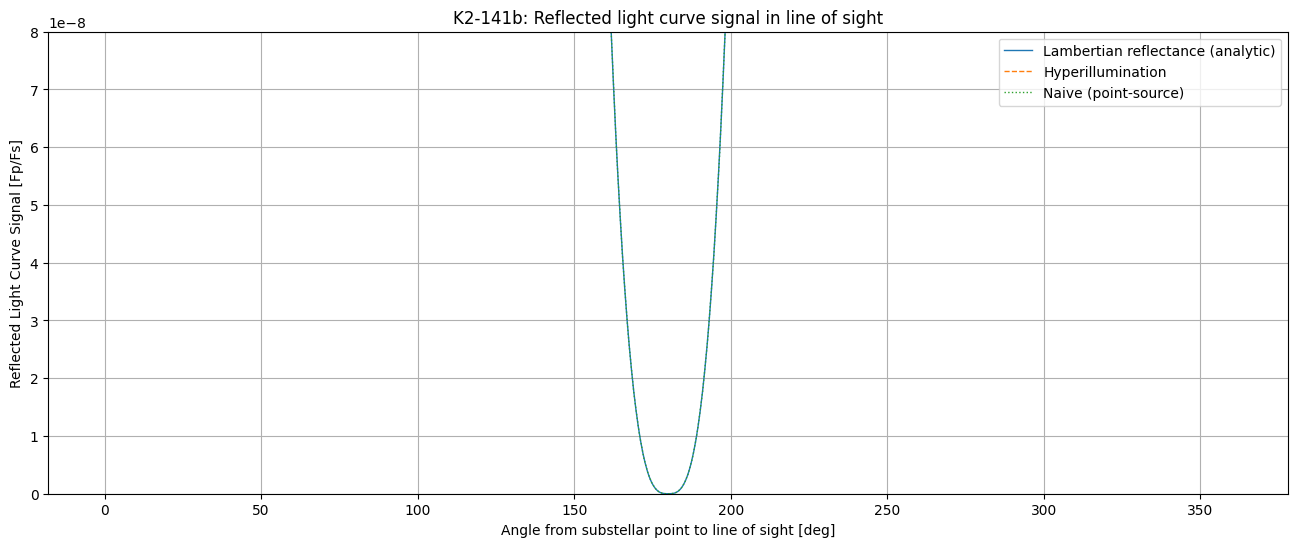

In [6]:
plt.figure(figsize=(16, 6))
plt.plot(epsilon, L_lambertian, linewidth=1, label="Lambertian reflectance (analytic)")
plt.plot(epsilon, L_kopal, linewidth=1, linestyle="--", label="Hyperillumination")
plt.plot(epsilon, L_naive, linewidth=1, linestyle=":", label="Naive (point-source)")

plt.xlabel("Angle from substellar point to line of sight [deg]")
plt.ylabel(r"Reflected Light Curve Signal [Fp/Fs]")
plt.title("K2-141b: Reflected light curve signal in line of sight")
plt.legend()
plt.ylim(0., 0.8e-7)
plt.grid()

## Reflected Phase Curve

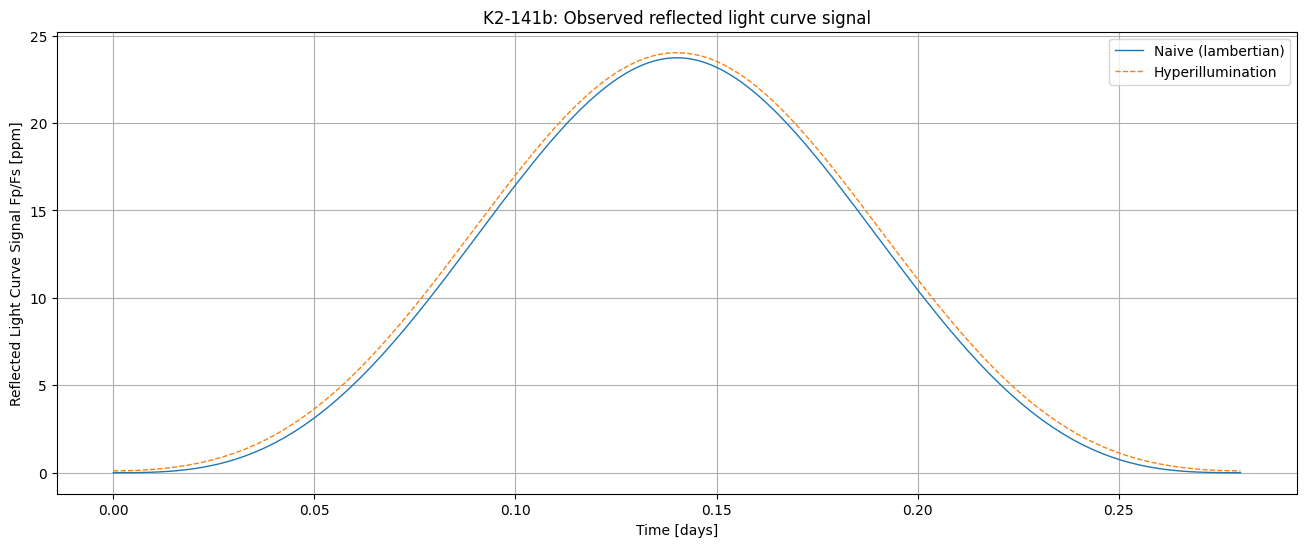

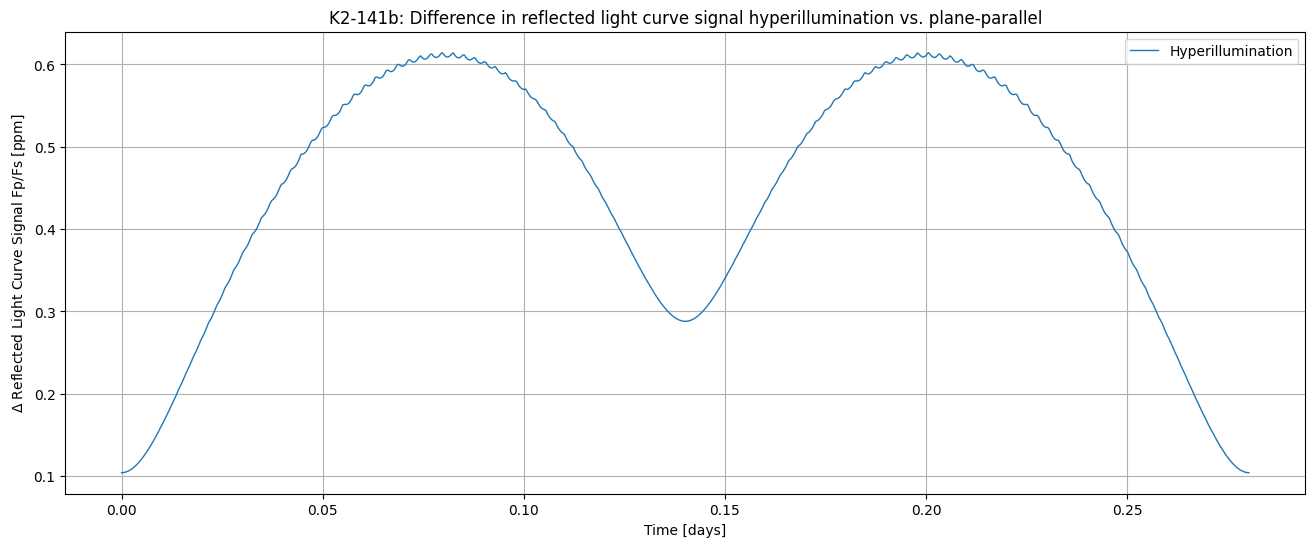

In [7]:
t = np.linspace(0, period, 1000)

orbital_ref_lightcurve_kopal = hipc.orbital_reflected_lightcurve(t, period, incl, ecc, w, rp, 1, a, T_eff, A=A)
orbital_ref_lightcurve_naive = hipc.orbital_reflected_lightcurve(t, period, incl, ecc, w, rp, 1, a, T_eff, insolation_model="naive", A=A)

plt.figure(figsize=(16, 6))
plt.plot(t, orbital_ref_lightcurve_naive*1e6, linewidth=1, label= "Naive (lambertian)")
plt.plot(t, orbital_ref_lightcurve_kopal*1e6, linewidth=1, linestyle="--", label="Hyperillumination")

plt.xlabel("Time [days]")
plt.ylabel(r"Reflected Light Curve Signal Fp/Fs [ppm]")
plt.title("K2-141b: Observed reflected light curve signal")
plt.legend()
#plt.ylim(0., 0.8e-7)
plt.grid()

plt.figure(figsize=(16, 6))
plt.plot(t, (orbital_ref_lightcurve_kopal-orbital_ref_lightcurve_naive)*1e6, linewidth=1, label="Hyperillumination")
plt.xlabel("Time [days]")
plt.ylabel(f"$\Delta$ Reflected Light Curve Signal Fp/Fs [ppm]")
plt.title("K2-141b: Difference in reflected light curve signal hyperillumination vs. plane-parallel")
plt.legend()
#plt.ylim(0., 0.8e-7)
plt.grid()

Wiggles are a numerical artefact in naive light curve signal caused by truncation at 90° (Gauss-Legendre converges exponentially only for smooth integrands). Can be fixed by setting n_phi = 320.

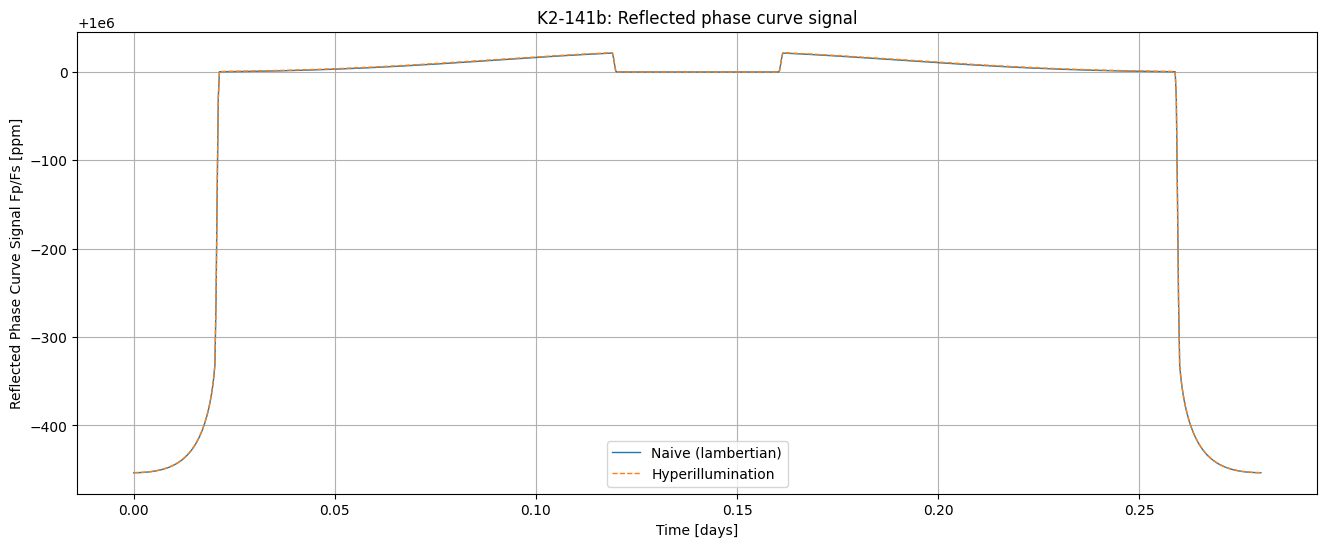

Occultation depth with Hyperillumination: 24.0 ppm   (measured: fp = 142 ppm at 4.5 um)
Occultation depth without Hyperillumination: 23.7 ppm   (measured: fp = 142 ppm at 4.5 um)


In [8]:
t_kopal, ref_phasecurve_kopal, ref_fp_kopal = hipc.reflected_PhaseCurve(period, incl, ecc, w, rp, 1, a, T_eff, rs, u=u, A=A)
t_naive, ref_phasecurve_naive, ref_fp_naive = hipc.reflected_PhaseCurve(period, incl, ecc, w, rp, 1, a, T_eff, rs, u=u, A=A, insolation_model="naive")

plt.figure(figsize=(16, 6))
plt.plot(t_naive, ref_phasecurve_naive*1e6, linewidth=1, label="Naive (lambertian)")
plt.plot(t_kopal, ref_phasecurve_kopal*1e6, linewidth=1, linestyle="--", label="Hyperillumination")

plt.xlabel("Time [days]")
plt.ylabel(r"Reflected Phase Curve Signal Fp/Fs [ppm]")
plt.title("K2-141b: Reflected phase curve signal")
plt.legend()
plt.grid()
plt.show()

print(f"Occultation depth with Hyperillumination: {ref_fp_kopal:.1f} ppm   (measured: fp = {fp*1e6:.0f} ppm at 4.5 um)")
print(f"Occultation depth without Hyperillumination: {ref_fp_naive:.1f} ppm   (measured: fp = {fp*1e6:.0f} ppm at 4.5 um)")